In [2]:
import pandas as pd
import tensorflow as tf

train_df = pd.read_csv('mnist_train.csv')
test_df  = pd.read_csv('mnist_test.csv')

# Alternative: Load Handwritten MNIST directly using Keras
# (X_train, y_train), (X_test, y_test) = tf.keras.datasets.mnist.load_data()

# Normalize pixel values
# X_train = X_train.astype('float32') / 255.0
# X_test = X_test.astype('float32') / 255.0

print("Train columns (first 5):", train_df.columns[:5].tolist())
print("Train shape:", train_df.shape)
print("Test shape:", test_df.shape)
print("\nFirst row (first 5 values):")
print(train_df.iloc[0, :5])

Train columns (first 5): ['5', '0', '0.1', '0.2', '0.3']
Train shape: (59999, 785)
Test shape: (9999, 785)

First row (first 5 values):
5      0
0      0
0.1    0
0.2    0
0.3    0
Name: 0, dtype: int64


In [4]:
import pandas as pd
import numpy as np

train_df = pd.read_csv('mnist_train.csv')
test_df  = pd.read_csv('mnist_test.csv')

# The first column is the label (whatever its name is)
# Position-based indexing (iloc) doesn't care about the column name
y_train    = train_df.iloc[:, 0].values.astype(np.int64)
X_train_raw = train_df.iloc[:, 1:].values.astype(np.float32)

y_test     = test_df.iloc[:, 0].values.astype(np.int64)
X_test_raw  = test_df.iloc[:, 1:].values.astype(np.float32)

# Normalize 0-255 -> 0-1
X_train_raw = X_train_raw / 255.0
X_test_raw  = X_test_raw  / 255.0

# Reshape (N, 784) -> (N, 28, 28) so Flatten(input_shape=(28,28)) works
X_train = X_train_raw.reshape(-1, 28, 28)
X_test  = X_test_raw .reshape(-1, 28, 28)

print(f"Training data shape: {X_train.shape}, labels: {y_train.shape}")
print(f"Test data shape:     {X_test.shape},  labels: {y_test.shape}")
print(f"Label range: {y_train.min()} to {y_train.max()}")

Training data shape: (59999, 28, 28), labels: (59999,)
Test data shape:     (9999, 28, 28),  labels: (9999,)
Label range: 0 to 9


In [5]:
from tensorflow.keras import layers, models

model = models.Sequential([
    layers.Input(shape=(28, 28)),              # avoids the input_shape warning
    layers.Flatten(),
    layers.Dense(128, activation='relu'),      # Hidden Layer 1
    layers.Dense(64,  activation='relu'),      # Hidden Layer 2
    layers.Dense(10,  activation='softmax')    # Output
])

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

history = model.fit(
    X_train, y_train,
    epochs=5,
    validation_split=0.1,
    batch_size=64
)

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ flatten (Flatten)                    │ (None, 784)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 128)                 │         100,480 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 64)                  │           8,256 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 10)                  │             650 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 109,386 (427.29 KB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 7s 7ms/step - accuracy: 0.9167 - loss: 0.2882 - val_accuracy: 0.9678 - val_loss: 0.1148
Epoch 2/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.9622 - loss: 0.1247 - val_accuracy: 0.9737 - val_loss: 0.0941
Epoch 3/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.9745 - loss: 0.0832 - val_accuracy: 0.9700 - val_loss: 0.0998
Epoch 4/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.9803 - loss: 0.0642 - val_accuracy: 0.9780 - val_loss: 0.0813
Epoch 5/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.9842 - loss: 0.0498 - val_accuracy: 0.9788 - val_loss: 0.0764


In [6]:
test_loss, test_acc = model.evaluate(X_test, y_test, verbose=2)
print(f"\nTest Accuracy: {test_acc:.4f}")

313/313 - 1s - 3ms/step - accuracy: 0.9766 - loss: 0.0766

Test Accuracy: 0.9766


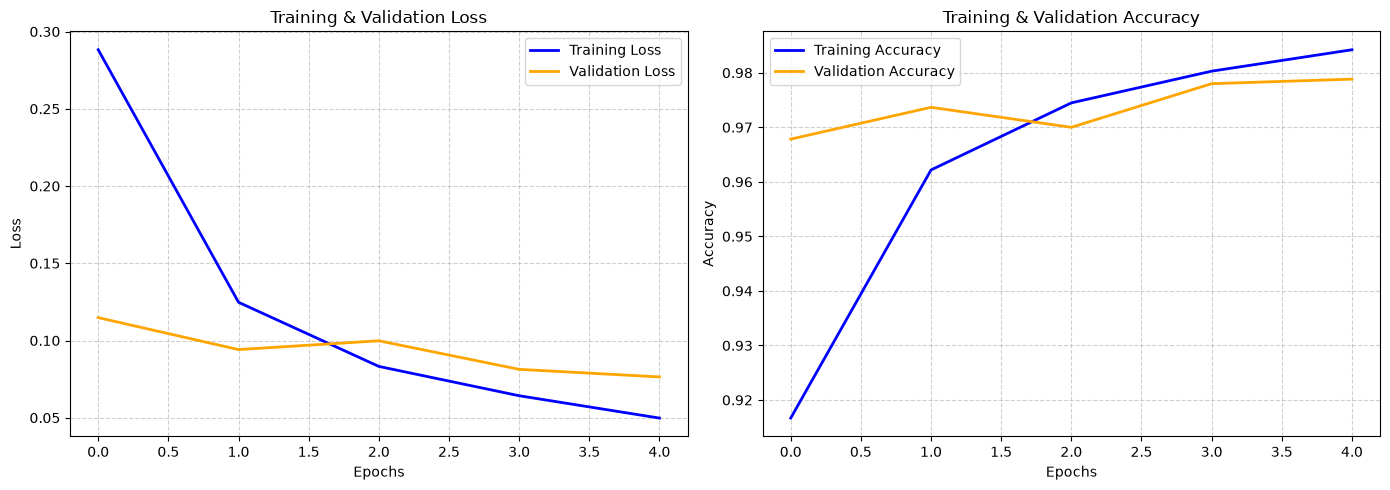

In [7]:
import matplotlib.pyplot as plt

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Loss
ax1.plot(history.history['loss'],     label='Training Loss',   color='blue',   lw=2)
ax1.plot(history.history['val_loss'], label='Validation Loss', color='orange', lw=2)
ax1.set_title('Training & Validation Loss')
ax1.set_xlabel('Epochs'); ax1.set_ylabel('Loss')
ax1.legend(); ax1.grid(True, linestyle='--', alpha=0.6)

# Accuracy
ax2.plot(history.history['accuracy'],     label='Training Accuracy',   color='blue',   lw=2)
ax2.plot(history.history['val_accuracy'], label='Validation Accuracy', color='orange', lw=2)
ax2.set_title('Training & Validation Accuracy')
ax2.set_xlabel('Epochs'); ax2.set_ylabel('Accuracy')
ax2.legend(); ax2.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

Model with 0 hidden layers  → Test Acc: 92.41%
Model with 2 hidden layers  → Test Acc: 97.66%


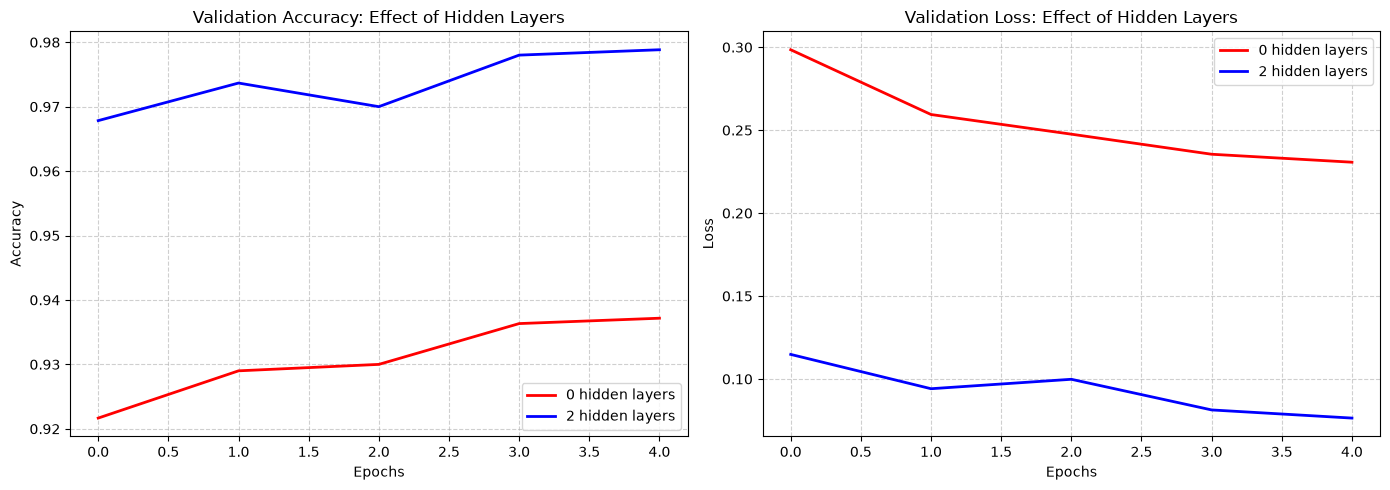

In [9]:
# Baseline: no hidden layers
baseline = models.Sequential([
    layers.Input(shape=(28, 28)),
    layers.Flatten(),
    layers.Dense(10, activation='softmax')   # 0 hidden layers
])
baseline.compile(optimizer='adam',
                 loss='sparse_categorical_crossentropy',
                 metrics=['accuracy'])

hist_base = baseline.fit(X_train, y_train, epochs=5,
                         validation_split=0.1, batch_size=64, verbose=0)
_, base_test_acc = baseline.evaluate(X_test, y_test, verbose=0)

print("=" * 55)
print(f"Model with 0 hidden layers  → Test Acc: {base_test_acc*100:.2f}%")
print(f"Model with 2 hidden layers  → Test Acc: {test_acc*100:.2f}%")
print("=" * 55)

# Comparison plot
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(hist_base.history['val_accuracy'], label='0 hidden layers', color='red',  lw=2)
ax1.plot(history.history['val_accuracy'],   label='2 hidden layers', color='blue', lw=2)
ax1.set_title('Validation Accuracy: Effect of Hidden Layers')
ax1.set_xlabel('Epochs'); ax1.set_ylabel('Accuracy')
ax1.legend(); ax1.grid(True, linestyle='--', alpha=0.6)

ax2.plot(hist_base.history['val_loss'], label='0 hidden layers', color='red',  lw=2)
ax2.plot(history.history['val_loss'],   label='2 hidden layers', color='blue', lw=2)
ax2.set_title('Validation Loss: Effect of Hidden Layers')
ax2.set_xlabel('Epochs'); ax2.set_ylabel('Loss')
ax2.legend(); ax2.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()